# Training a Real Model with Gradient Descent 

We want to predict a student's **final exam score** based on the **number of hours they studied**.

---

### The Model (Plain English):
```
predicted_exam_score = (score_boost_per_hour * study_hours) + baseline_score
```

* **`score_boost_per_hour` (The Weight):** How many extra points a student gains for every additional hour of studying.
* **`baseline_score` (The Bias):** The baseline score a student would get with zero study hours, just from general knowledge.
* **Our Goal with Gradient Descent:** The computer starts with random guesses for these two dials, measures how wrong it is, and turns the dials slightly until it makes accurate predictions.


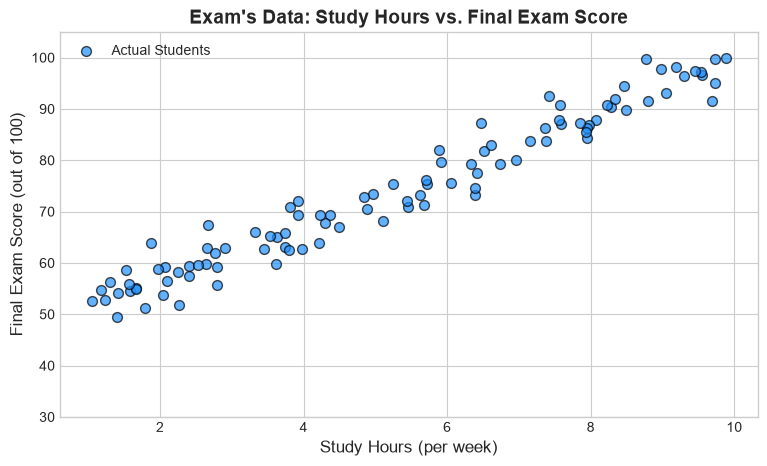

Collected data for 100 students.
Example student 1: Studied 4.4 hours -> Scored 69.3 points
Example student 2: Studied 9.6 hours -> Scored 96.5 points


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = [9, 5]
np.random.seed(42)

# --- Real-World Scenario: 100 StudentGator Students ---
total_students = 100

# Study hours range between 1.0 and 10.0 hours
study_hours = np.random.uniform(low=1.0, high=10.0, size=(total_students, 1))

# Real underlying truth (Hidden from the model!):
# Each hour adds ~5.5 points, and students start with a baseline score of ~45 points.
# We also add some random realistic student variance (+/- a few points).
true_score_boost_per_hour = 5.5
true_baseline_score = 45.0
random_variation = np.random.normal(loc=0.0, scale=3.5, size=(total_students, 1))

actual_exam_scores = (true_score_boost_per_hour * study_hours) + true_baseline_score + random_variation
# Keep scores between 0 and 100
actual_exam_scores = np.clip(actual_exam_scores, 0.0, 100.0)

# Plot our student data
plt.scatter(study_hours, actual_exam_scores, color='dodgerblue', alpha=0.7, edgecolors='k', s=50, label='Actual Students')
plt.title("Exam's Data: Study Hours vs. Final Exam Score", fontsize=14, fontweight='bold')
plt.xlabel("Study Hours (per week)", fontsize=12)
plt.ylabel("Final Exam Score (out of 100)", fontsize=12)
plt.ylim(30, 105)
plt.legend()
plt.show()

print(f"Collected data for {total_students} students.")
print(f"Example student 1: Studied {study_hours[0][0]:.1f} hours -> Scored {actual_exam_scores[0][0]:.1f} points")
print(f"Example student 2: Studied {study_hours[1][0]:.1f} hours -> Scored {actual_exam_scores[1][0]:.1f} points")


---
## Step 1: The Model's Blind First Guess

Before training, the model has no idea what the real numbers are. 
It starts with a random, terrible guess:
* `score_boost_per_hour = 1.0` *(thinks 1 hour of study only gives 1 point)*
* `baseline_score = 20.0` *(thinks students score 20 by default)*

Let's see how bad this first guess is:


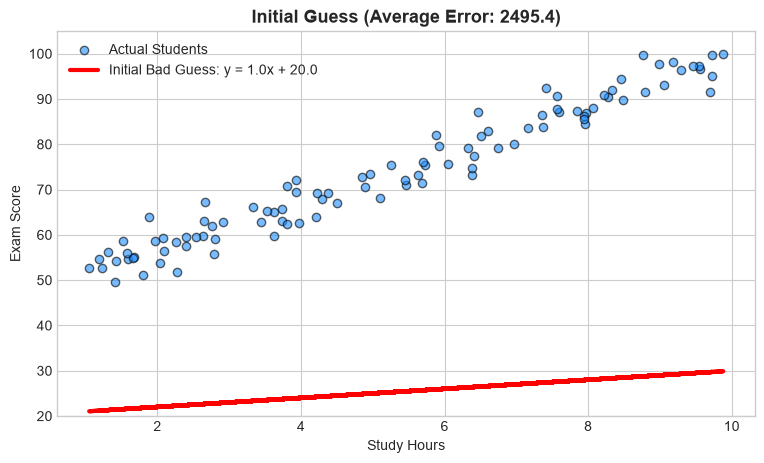

Average Squared Error of initial guess: 2495.42 (Way too high!)


In [2]:
# Initial blind guesses
score_boost_per_hour = np.array([1.0])
baseline_score = np.array([20.0])

# Make predictions with our bad guess
predicted_exam_scores = (score_boost_per_hour * study_hours) + baseline_score

# Calculate how wrong we are (Mean Squared Error)
prediction_errors = predicted_exam_scores - actual_exam_scores
average_squared_error = np.mean(prediction_errors ** 2)

# Plot the bad guess against real students
plt.scatter(study_hours, actual_exam_scores, color='dodgerblue', alpha=0.6, edgecolors='k', label='Actual Students')
plt.plot(study_hours, predicted_exam_scores, color='red', lw=3, label=f'Initial Bad Guess: y = {score_boost_per_hour[0]}x + {baseline_score[0]}')
plt.title(f"Initial Guess (Average Error: {average_squared_error:.1f})", fontsize=13, fontweight='bold')
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.ylim(20, 105)
plt.legend()
plt.show()

print(f"Average Squared Error of initial guess: {average_squared_error:.2f} (Way too high!)")


---
## Step 2: Training with Gradient Descent

To fix the model, we use the **4-step training loop**:

1. **Forward Pass:** Make predictions using the current dials (`score_boost_per_hour` and `baseline_score`).
2. **Calculate Error:** Measure how far off our predictions are from reality (`predicted - actual`).
3. **Calculate the Slopes (Gradients):**
   * *If the slope is positive:* Our dial is too high $\rightarrow$ turn it down.
   * *If the slope is negative:* Our dial is too low $\rightarrow$ turn it up.
4. **Update the Dials (Gradient Descent Step):**
   * `dial = dial - (learning_rate * slope)`

Let's run this loop for **400 steps** and watch the model learn!


In [3]:
# Start fresh with our bad guesses
score_boost_per_hour = np.array([1.0])
baseline_score = np.array([20.0])

# How big of a step to take each time
learning_rate = 0.01
total_epochs = 400

# Track our progress over time
error_history = []
boost_dial_history = [float(score_boost_per_hour[0])]
baseline_dial_history = [float(baseline_score[0])]

for epoch in range(1, total_epochs + 1):
    # 1. Forward Pass: Make predictions
    predicted_exam_scores = (score_boost_per_hour * study_hours) + baseline_score
    
    # 2. Measure Error: How far off are we?
    prediction_errors = predicted_exam_scores - actual_exam_scores
    current_error = np.mean(prediction_errors ** 2)
    error_history.append(current_error)
    
    # 3. Calculate Slopes (Gradients)
    # The slope tells us which direction increases the error.
    # We want to go the OPPOSITE way to decrease error.
    slope_for_boost_dial = (2.0 / total_students) * np.sum(prediction_errors * study_hours)
    slope_for_baseline_dial = (2.0 / total_students) * np.sum(prediction_errors)
    
    # 4. Gradient Descent Step: Turn the dials slightly in the direction that lowers error
    score_boost_per_hour -= learning_rate * slope_for_boost_dial
    baseline_score -= learning_rate * slope_for_baseline_dial
    
    # Save values for plotting
    boost_dial_history.append(float(score_boost_per_hour[0]))
    baseline_dial_history.append(float(baseline_score[0]))
    
    # Print progress every 100 steps
    if epoch % 100 == 0:
        print(f"Step {epoch:3d} | Current Error: {current_error:.2f} | Points/Hour: {score_boost_per_hour[0]:.2f} | Baseline: {baseline_score[0]:.2f}")

print("")
print("--- Training Complete ---")
print(f"Learned Score Boost per Hour: {score_boost_per_hour[0]:.2f} (True Hidden Value was {true_score_boost_per_hour})")
print(f"Learned Baseline Score:       {baseline_score[0]:.2f} (True Hidden Value was {true_baseline_score})")


Step 100 | Current Error: 66.53 | Points/Hour: 7.83 | Baseline: 29.45
Step 200 | Current Error: 35.11 | Points/Hour: 6.99 | Baseline: 34.94
Step 300 | Current Error: 21.08 | Points/Hour: 6.43 | Baseline: 38.60
Step 400 | Current Error: 14.82 | Points/Hour: 6.06 | Baseline: 41.05

--- Training Complete ---
Learned Score Boost per Hour: 6.06 (True Hidden Value was 5.5)
Learned Baseline Score:       41.05 (True Hidden Value was 45.0)


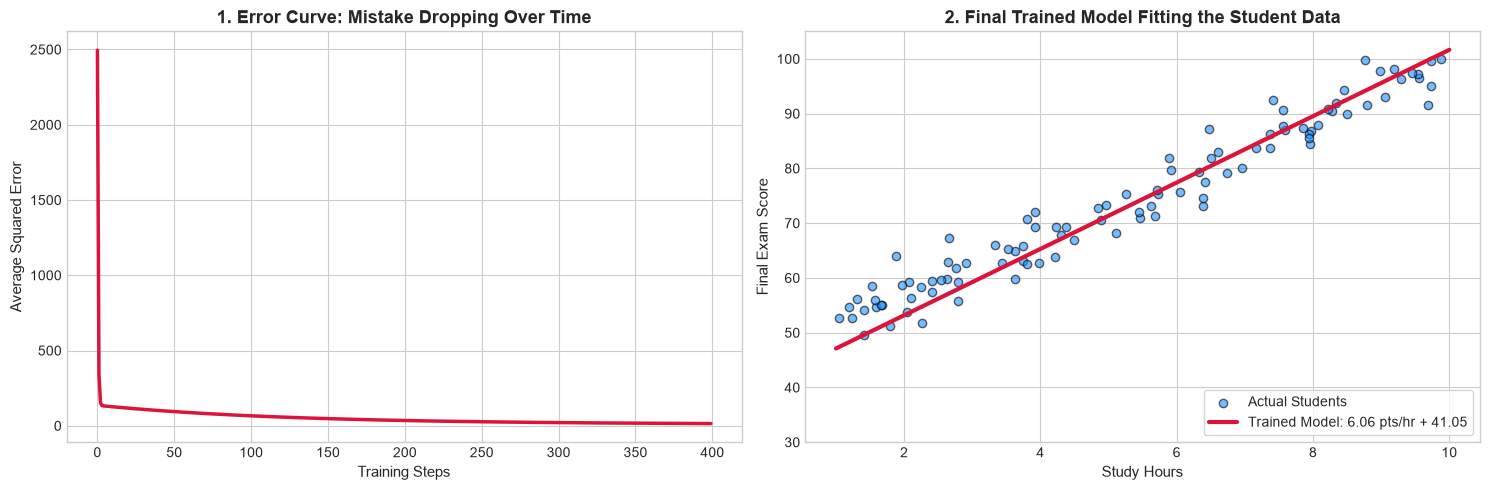

In [4]:
# Let's inspect the results visually!
fig, (plot_error, plot_fit) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Error dropping over time
plot_error.plot(error_history, color='crimson', lw=2.5)
plot_error.set_title("1. Error Curve: Mistake Dropping Over Time", fontsize=13, fontweight='bold')
plot_error.set_xlabel("Training Steps", fontsize=11)
plot_error.set_ylabel("Average Squared Error", fontsize=11)

# Plot 2: Final Model Line vs Real Students
plot_fit.scatter(study_hours, actual_exam_scores, color='dodgerblue', alpha=0.6, edgecolors='k', label='Actual Students')

# Draw our trained prediction line
hours_line = np.linspace(1, 10, 100).reshape(-1, 1)
trained_predictions = (score_boost_per_hour * hours_line) + baseline_score
plot_fit.plot(hours_line, trained_predictions, color='crimson', lw=3, 
              label=f'Trained Model: {score_boost_per_hour[0]:.2f} pts/hr + {baseline_score[0]:.2f}')

plot_fit.set_title("2. Final Trained Model Fitting the Student Data", fontsize=13, fontweight='bold')
plot_fit.set_xlabel("Study Hours", fontsize=11)
plot_fit.set_ylabel("Final Exam Score", fontsize=11)
plot_fit.set_ylim(30, 105)
plot_fit.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()


---
## Step 3: Why `learning_rate` Is So Important

The **learning rate** controls how aggressively you turn the dials at each step:
* **Too Small (`0.0005`):** The model takes microscopic baby steps. It will take thousands of steps just to improve a little.
* **Just Right (`0.01`):** Smooth, steady progress straight to the best fit.
* **Too Large (`0.045`):** The model turns the dial too far, overshoots the target, bounces violently out of control, and **diverges (explodes)**!

Let's test all three on our student model:


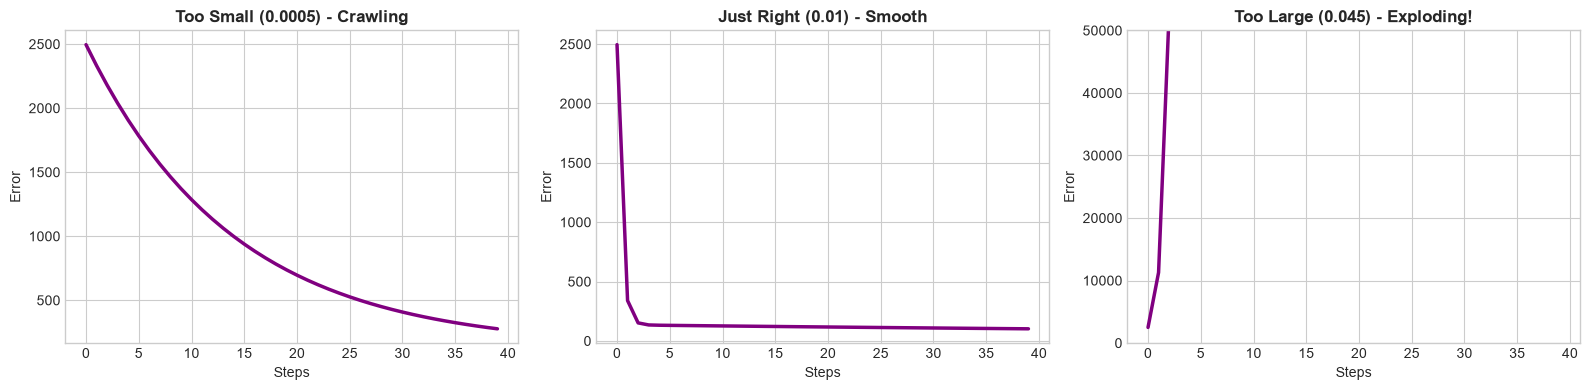

In [5]:
test_learning_rates = [0.0005, 0.01, 0.045]
labels = ["Too Small (0.0005) - Crawling", "Just Right (0.01) - Smooth", "Too Large (0.045) - Exploding!"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for current_axis, lr_choice, label_text in zip(axes, test_learning_rates, labels):
    # Start from scratch
    temp_boost = np.array([1.0])
    temp_base = np.array([20.0])
    temp_errors = []
    
    for _ in range(40):
        preds = (temp_boost * study_hours) + temp_base
        err = preds - actual_exam_scores
        temp_errors.append(np.mean(err ** 2))
        
        # Slopes
        slope_boost = (2.0 / total_students) * np.sum(err * study_hours)
        slope_base = (2.0 / total_students) * np.sum(err)
        
        # Step
        temp_boost -= lr_choice * slope_boost
        temp_base -= lr_choice * slope_base
    
    current_axis.plot(temp_errors, color='purple', lw=2.5)
    current_axis.set_title(label_text, fontsize=12, fontweight='bold')
    current_axis.set_xlabel("Steps")
    current_axis.set_ylabel("Error")
    
    # Cap y-axis display so exploding plot doesn't distort
    if lr_choice == 0.045:
        current_axis.set_ylim(0, 50000)

plt.tight_layout()
plt.show()


---
## Step 4: Upgrading to Modern Optimizers (SGD vs. Adam)

Why did the AI industry invent **Adam**?

Notice in our student example:
* `study_hours` is between 1 and 10, so its slope is naturally large.
* `baseline_score` has no multiplier, so its slope is much smaller.

With plain Gradient Descent, one dial changes fast while the other crawls.
* **Adam (Adaptive Moment Estimation):** It automatically gives **each dial its own custom step size** and adds momentum (like a heavy bowling ball) to smooth out bounces.

Let's see how **Adam** compares to **Plain Gradient Descent** on our student data:


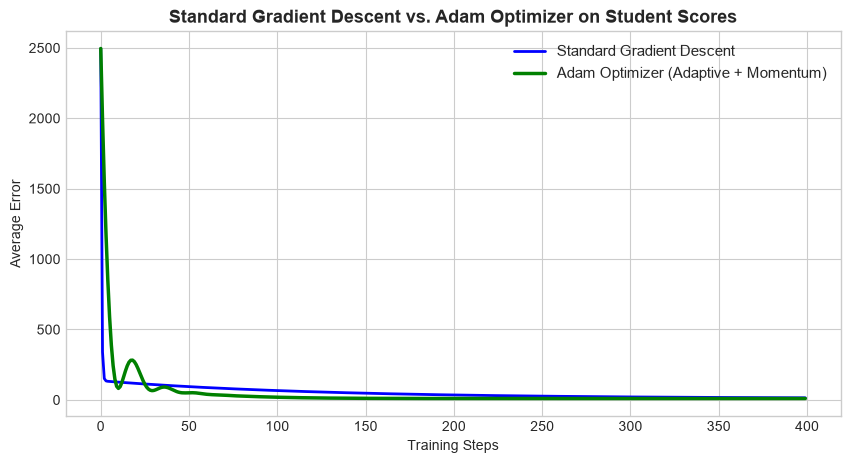

Standard GD final values: 6.06 pts/hr, baseline = 41.05
Adam Optimizer final values: 5.31 pts/hr, baseline = 45.98
True hidden values were:    5.50 pts/hr, baseline = 45.00


In [6]:
# Run Adam Optimizer from scratch on the exact same student data
adam_boost = np.array([1.0])
adam_base = np.array([20.0])
adam_learning_rate = 0.8  # Adam uses adaptive scaling, so you can safely use a higher learning rate!

# Adam tracking variables (velocity and scale for each parameter)
momentum_boost, momentum_base = 0.0, 0.0
scale_tracker_boost, scale_tracker_base = 0.0, 0.0
beta_velocity = 0.9
beta_scale = 0.999
small_safety_number = 1e-8

adam_error_history = []

for step in range(1, 401):
    # 1. Forward Pass
    adam_preds = (adam_boost * study_hours) + adam_base
    adam_err = adam_preds - actual_exam_scores
    adam_error_history.append(np.mean(adam_err ** 2))
    
    # 2. Slopes
    slope_boost = (2.0 / total_students) * np.sum(adam_err * study_hours)
    slope_base = (2.0 / total_students) * np.sum(adam_err)
    
    # 3. Adam Magic: Track velocity (momentum)
    momentum_boost = beta_velocity * momentum_boost + (1.0 - beta_velocity) * slope_boost
    momentum_base = beta_velocity * momentum_base + (1.0 - beta_velocity) * slope_base
    
    # 4. Adam Magic: Track scale of past slopes
    scale_tracker_boost = beta_scale * scale_tracker_boost + (1.0 - beta_scale) * (slope_boost ** 2)
    scale_tracker_base = beta_scale * scale_tracker_base + (1.0 - beta_scale) * (slope_base ** 2)
    
    # 5. Bias correction for the first few steps
    corrected_momentum_boost = momentum_boost / (1.0 - beta_velocity ** step)
    corrected_momentum_base = momentum_base / (1.0 - beta_velocity ** step)
    corrected_scale_boost = scale_tracker_boost / (1.0 - beta_scale ** step)
    corrected_scale_base = scale_tracker_base / (1.0 - beta_scale ** step)
    
    # 6. Adam Update Step (Adapts step size per dial!)
    adam_boost -= (adam_learning_rate / (np.sqrt(corrected_scale_boost) + small_safety_number)) * corrected_momentum_boost
    adam_base -= (adam_learning_rate / (np.sqrt(corrected_scale_base) + small_safety_number)) * corrected_momentum_base

# Compare Error Curves Side-by-Side!
plt.figure(figsize=(10, 5))
plt.plot(error_history, label="Standard Gradient Descent", color='blue', lw=2)
plt.plot(adam_error_history, label="Adam Optimizer (Adaptive + Momentum)", color='green', lw=2.5)
plt.title("Standard Gradient Descent vs. Adam Optimizer on Student Scores", fontsize=13, fontweight='bold')
plt.xlabel("Training Steps")
plt.ylabel("Average Error")
plt.legend(fontsize=11)
plt.show()

print(f"Standard GD final values: {score_boost_per_hour[0]:.2f} pts/hr, baseline = {baseline_score[0]:.2f}")
print(f"Adam Optimizer final values: {adam_boost[0]:.2f} pts/hr, baseline = {adam_base[0]:.2f}")
print(f"True hidden values were:    {true_score_boost_per_hour:.2f} pts/hr, baseline = {true_baseline_score:.2f}")


---
## Key Engineering Takeaways 📋

1. **What is a Model?** Just a simple equation like `predicted = (weight * input) + bias`.
2. **What is Training?** Starting with bad guesses for `weight` and `bias`, and slowly adjusting them until predictions match reality.
3. **What is a Gradient?** The direction that makes error worse. We step the **opposite way** to make error smaller.
4. **What is `learning_rate`?** How far you turn the dial at each step. Too small = slow training; too large = exploding error.
5. **Why Adam is the Industry Default:** Because it gives each dial its own custom step size and builds momentum, finding the right weights much faster than basic gradient descent.

In modern frameworks like **PyTorch** or **TensorFlow**, all of these 20 lines of math are handled automatically behind the scenes with a single line:
```python
optimizer.step()
```
Now you know exactly what is happening inside that single line!
